# QuantumXCT — simulated data (object-oriented version)

OO reproduction of `qxct_pred_classic_sim.py` using the new `QuantumXct` + `RunConfig` API. The original script is left untouched; this notebook produces the same pipeline (encode → density-matrix candidate screening → topology search → CRX-angle optimization → ablation analysis) through the config-driven interface.

**Convention:** mono-culture (`Lone`) = basal/initial state, co-culture (`Interact`) = target. Qubit layout: cell 1 → q0..q1 (`gl_ct1`), cell 2 → q2..q5 (`gl_ct2`). Run this notebook from the `python/` folder so the `simCellsSpace/...` path resolves.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc

from qxct import (
    QuantumXct, RunConfig,
    EncodingConfig, BackendConfig, SearchConfig, OptimizerConfig, MitigationConfig,
    build_optimized_circuit, plot_measurement_histograms,
)
from qxct.encoding import create_joint_histogram, plot_joint_histogram

np.random.seed(42)

/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/scanpy/_utils/__init__.py:27: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version


/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/scanpy/__init__.py:36: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/scanpy/readwrite.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


## 1. Load & preprocess the simulated dataset

In [2]:
adata = sc.read_h5ad("simCellsSpace/sim_cells_datasets_co_mo_simulated_classical.h5ad")
adata.X = adata.layers['counts']
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 4000 × 120
    obs: 'cell_type'
    uns: 'cell_type_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## 2. Gene lists (qubit order)

Cell 1 = `gl_ct1` (q0, q1); cell 2 = `gl_ct2` (q2..q5).

In [3]:
gl_ct1 = ["Gene_50", "Gene_90"]                      # source A, spatial feedback in A
gl_ct2 = ["Gene_60", "Gene_70", "Gene_71", "Gene_80"]  # target/GRN/source in B
gl_all = gl_ct1 + gl_ct2
gl_all

['Gene_50', 'Gene_90', 'Gene_60', 'Gene_70', 'Gene_71', 'Gene_80']

## 3. Subset cell types and binarize (> 0)

Interacting (co): `Type_A_Interact` / `Type_B_Interact`. Lone (mono): `Type_A_Lone` / `Type_B_Lone`.

In [4]:
from scipy.sparse import issparse

def _mat(a):
    return a.X.toarray() if issparse(a.X) else a.X

# Interacting (co-culture) -> target
ict1 = adata.obs["cell_type"] == 'Type_A_Interact'
ict2 = adata.obs["cell_type"] == 'Type_B_Interact'
Xct1_co = _mat(adata[ict1, gl_ct1].copy())
Xct2_co = _mat(adata[ict2, gl_ct2].copy())

# Lone (mono-culture) -> basal
lct1 = adata.obs["cell_type"] == 'Type_A_Lone'
lct2 = adata.obs["cell_type"] == 'Type_B_Lone'
Xct1_mo = _mat(adata[lct1, gl_ct1])
Xct2_mo = _mat(adata[lct2, gl_ct2])

# Binarize against 0 (mean * 0), exactly as the original script
Xct1_binary_co = (Xct1_co > np.mean(Xct1_co, axis=0) * 0).astype(int)
Xct2_binary_co = (Xct2_co > np.mean(Xct2_co, axis=0) * 0).astype(int)
Xct1_binary_mo = (Xct1_mo > np.mean(Xct1_mo, axis=0) * 0).astype(int)
Xct2_binary_mo = (Xct2_mo > np.mean(Xct2_mo, axis=0) * 0).astype(int)

## 4. Joint histograms (quantum-state inputs)

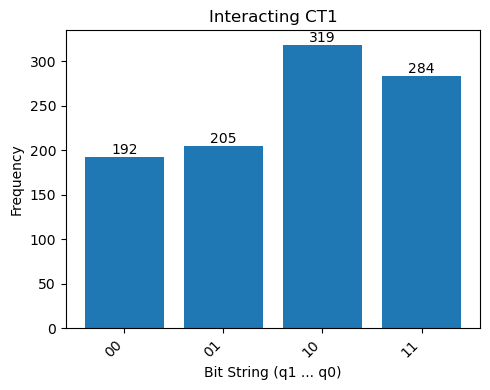

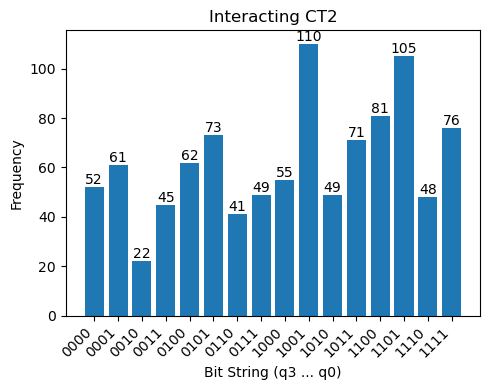

CT1 co: Counter({'10': 319, '11': 284, '01': 205, '00': 192})
CT2 co: Counter({'1001': 110, '1101': 105, '1100': 81, '1111': 76, '0101': 73, '1011': 71, '0100': 62, '0001': 61, '1000': 55, '0000': 52, '0111': 49, '1010': 49, '1110': 48, '0011': 45, '0110': 41, '0010': 22})


In [5]:
joint_counts_ct1_co, _ = create_joint_histogram(Xct1_binary_co)
joint_counts_ct2_co, _ = create_joint_histogram(Xct2_binary_co)
joint_counts_ct1_mo, _ = create_joint_histogram(Xct1_binary_mo)
joint_counts_ct2_mo, _ = create_joint_histogram(Xct2_binary_mo)

plot_joint_histogram(joint_counts_ct1_co, num_qubits=len(gl_ct1), title='Interacting CT1')
plot_joint_histogram(joint_counts_ct2_co, num_qubits=len(gl_ct2), title='Interacting CT2')
print("CT1 co:", joint_counts_ct1_co)
print("CT2 co:", joint_counts_ct2_co)

## 5. Configure the run

`threshold=0.005`, `search_mode="pos"`, `nshots=5000` — matching the original script. `EncodingConfig(norm="l1")` is the default (frequency-preserving).

In [6]:
config = RunConfig(
    encoding=EncodingConfig(norm="l1"),
    backend=BackendConfig(shots=5000),
    search=SearchConfig(
        algorithm="multi_epoch",       # switch to 'iterative_n_wise' to mirror that block
        candidate_scope="all",         # GRN + LR
        threshold=0.005, search_mode="pos",
        n_epochs=None, kl_tol=0.05, max_greedy_depth=30,
    ),
    optimizer=OptimizerConfig(method="COBYLA", initial_angle=np.pi / 2),
    mitigation=MitigationConfig(dynamical_decoupling=True, twirling_gates=True,
                                twirling_measure=True, measurement_mitigation=True,
                                resilience_level=1, shots=5000),
)

## 6. Run the pipeline

`encode(basal_ct1, basal_ct2, interacting_ct1, interacting_ct2)` → `run()` does screen → search → optimize → analyze.

In [7]:
qx = QuantumXct(config, gene_list=gl_all)
qx.encode(joint_counts_ct1_mo, joint_counts_ct2_mo, joint_counts_ct1_co, joint_counts_ct2_co)

result = qx.run()
print("Best topology :", result.topology)
print("CRX angles    :", [round(a, 3) for a in result.angles])
print("Final KL sum  :", round(result.kl_sum, 4))


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 30


Initial KL divergence (baseline): 2.486456

--- Starting Epoch 1/30 (Addition) with CNOT: (3, 5) (KL: 2.427692) ---


    --> Found a better KL on this path: 2.051647 at depth 2 with added CNOT (0, 2)


    --> Found a better KL on this path: 1.716767 at depth 3 with added CNOT (0, 4)


    --> Found a better KL on this path: 1.426912 at depth 4 with added CNOT (0, 5)


...

    --> Found a better KL on this path: 0.723385 at depth 10 with added CNOT (3, 2)


    --> Found a better KL on this path: 0.712930 at depth 11 with added CNOT (4, 5)


  Epoch 29 best KL Sum: 0.712930

--- Starting Epoch 30/30 (Addition) with CNOT: (4, 0) (KL: 2.487876) ---
  Skipping epoch: Single CNOT KL (2.487876) does not improve over baseline (2.486456).

Final Result: Best sequence found has 13 CNOTs (KL: 0.631689).

Total search took: 550.93 seconds.

--- Starting CRX Angle Optimization (13 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 102   Least value of F = 0.6038441088051916   Constraint violation = 0.0
The corresponding X is:
[2.59988692 1.48961407 1.55261333 1.70777216 1.59928581 1.33229384
 1.43339784 1.52200584 1.62177818 1.48747869 1.48185839 1.52331609
 1.54396385]
The constraint value is:
[-2.59988692 -1.48961407 -1.55261333 -1.70777216 -1.59928581 -1.33229384
 -1.43339784 -1.52200584 -1.62177818 -1.48747869 -1.48185839 -1.52331609
 -1.54396385 -0.54170574 -1.65197859 -1.58897933 -1.43382049 -1.54230684
 -1.80929881 -1.70819481 -1.61958681 -1.51981447 -1.65411397 -1.65973426
 -1.61827657 -1.5976288 ]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['2.5999', '1.4896', '1.5526', '1.7078', '1.5993', '1.3323', '1.4334', '1.5220', '1.6218', '1.4875', '1.4819', '1.5233', '1.5440']
CRX Angle Optimization took: 7.


--- Gate Contribution Analysis (Ablation Study) ---
    Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0      0  Baseline (0 gates)             nan        2.4865    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1      1  Gene_60 -> Gene_90          2.5999        2.3358   -0.1506                 -0.1506      2.3358             0.1506          6.06%                   6.06%                8.00%         148.96°
2      2  Gene_50 -> Gene_60          1.4896        1.9101   -0.4257                 -0.5763      2.1276             0.3588         17.12%                  14.43%               22.61%          85.35°
3      3  Gene_50 -> Gene_80          1.5526        1.5723   -0.3379                 -0.9142      2.1649             0.3215         13.59%         

In [8]:
result.contribution_df

,Step,Interaction,CRX Angle (rad),KL Divergence,KL Change,Cumulative KL Reduction,Isolated KL,Isolated Reduction,% Contribution,% Isolated Contribution,% of Total Reduction,CRX Angle (deg)
0,0,Baseline (0 gates),NaN,2.486456,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,-0.000000,NaN
1,1,Gene_60 -> Gene_90,2.599887,2.335837,-0.150619,-0.150619,2.335837,0.150619,6.057572,6.057572,8.000527,148.962547
2,2,Gene_50 -> Gene_60,1.489614,1.910148,-0.425689,-0.576308,2.127628,0.358827,17.120318,14.431273,22.611627,85.348599
3,3,Gene_50 -> Gene_80,1.552613,1.572254,-0.337893,-0.914201,2.164944,0.321512,13.589354,12.930540,17.948113,88.958191
4,4,Gene_50 -> Gene_71,1.707772,1.250951,-0.321304,-1.235505,2.089168,0.397287,12.922160,15.978058,17.066919,97.848137
5,5,Gene_50 -> Gene_90,1.599286,1.054325,-0.196626,-1.432131,2.232339,0.254116,7.907863,10.220016,10.444296,91.632327
6,6,Gene_50 -> Gene_70,1.332294,0.901312,-0.153013,-1.585143,2.335335,0.151121,6.153848,6.077760,8.127683,76.334814
7,7,Gene_90 -> Gene_50,1.433398,0.811368,-0.089944,-1.675087,2.486689,-0.000234,3.617369,-0.009399,4.777633,82.127647
8,8,Gene_90 -> Gene_80,1.522006,0.738397,-0.072972,-1.748059,2.413089,0.073367,2.934763,2.950659,3.876083,87.204511
9,9,Gene_90 -> Gene_60,1.621778,0.707989,-0.030408,-1.778467,2.384989,0.101466,1.222944,4.080765,1.615201,92.921045


## 7. Measurement histograms of the optimized circuit


--- Running circuit for: CRX-Optimized (OO) ---
Counts for c_measure1: {'01': 879, '00': 2055, '10': 1006, '11': 1060}
Counts for c_measure2: {'0101': 180, '0000': 1709, '1100': 250, '1011': 354, '0100': 201, '1001': 458, '1000': 330, '0001': 317, '1101': 333, '0011': 99, '1111': 279, '0111': 146, '0010': 101, '1110': 101, '1010': 115, '0110': 27}


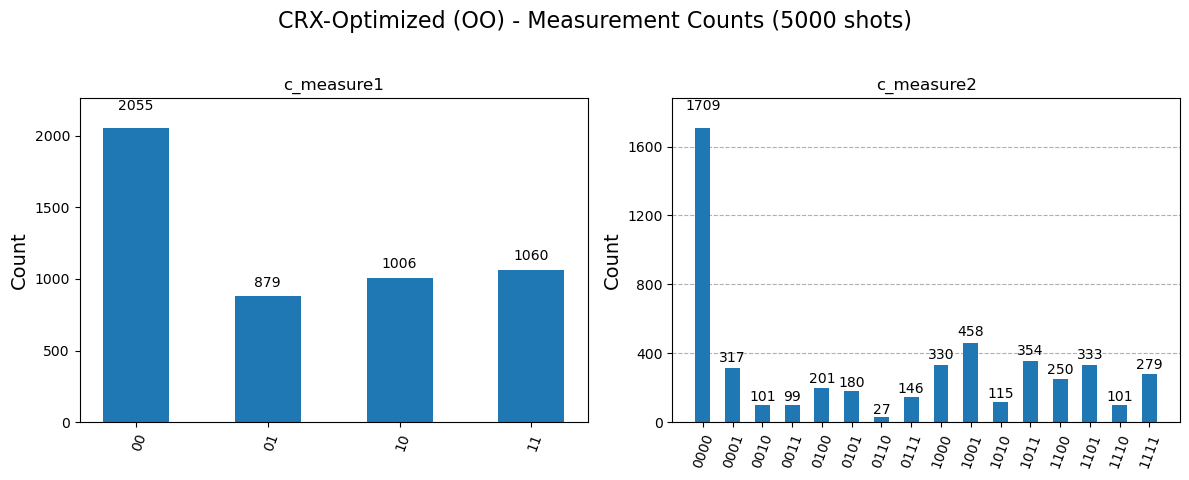

({'01': 879, '00': 2055, '10': 1006, '11': 1060},
 {'0101': 180,
  '0000': 1709,
  '1100': 250,
  '1011': 354,
  '0100': 201,
  '1001': 458,
  '1000': 330,
  '0001': 317,
  '1101': 333,
  '0011': 99,
  '1111': 279,
  '0111': 146,
  '0010': 101,
  '1110': 101,
  '1010': 115,
  '0110': 27})

In [9]:
final_circ = build_optimized_circuit(qx.circ1, qx.circ2, result.topology, result.angles)
plot_measurement_histograms(final_circ, nshots=5000, title_prefix="CRX-Optimized (OO)")

## 8. Hardware 'assert quality' (optional)

Pass a real IBM backend to run the optimized circuit once on hardware with the mitigation options in `config`. Here the local Aer simulator stands in.

In [10]:
# from qiskit_ibm_runtime import QiskitRuntimeService
# backend = QiskitRuntimeService().least_busy(operational=True, simulator=False)
# hw = qx.assert_on_hardware(backend=backend)
hw = qx.assert_on_hardware()
print("assert-quality KL total:", round(hw["kl_total"], 4), "| backend:", hw["backend"])

assert-quality KL total: 0.5933 | backend: aer_simulator


/home/ssromerogon/github_repos/QuantumXCT/python/qxct/hardware.py:106: UserWarning: resilience_level is not a SamplerV2 option and is ignored; readout correction is applied in assert_quality instead.
  warnings.warn("resilience_level is not a SamplerV2 option and is ignored; "
/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/qiskit_ibm_runtime/fake_provider/local_service.py:274: UserWarning: Options {'dynamical_decoupling': {'enable': True, 'sequence_type': 'XX'}, 'twirling': {'enable_gates': True, 'enable_measure': True}} have no effect in local testing mode.
  warnings.warn(f"Options {options_copy} have no effect in local testing mode.")


## 9. Save

In [11]:
qx.save("results/classic_sim_oo", metadata={"dataset": "sim_cells_co_mo", "search_mode": "pos"})

Topology saved → results/classic_sim_oo.json
Ablation results saved → results/classic_sim_oo_ablation.csv


'results/classic_sim_oo'

## Compare all search algorithms

Runs each `SearchConfig.algorithm` on the *same* data and tabulates gates / final KL / reduction, so you can compare **multi_epoch**, **iterative_n_wise** and **vqe_hybrid** side by side — the OO equivalent of the original script's separate search blocks.

`vqe_hybrid` builds an EfficientSU2 ansatz with one qubit per candidate CNOT, so it is the heaviest variant. Each run is kept in `algo_runs[...]` for further inspection (topology, angles, `assert_on_hardware`, `contribution_df`).


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 30
Initial KL divergence (baseline): 2.486456

--- Starting Epoch 1/30 (Addition) with CNOT: (3, 5) (KL: 2.427692) ---


    --> Found a better KL on this path: 2.051647 at depth 2 with added CNOT (0, 2)


    --> Found a better KL on this path: 1.716767 at depth 3 with added CNOT (0, 4)


    --> Found a better KL on this path: 1.426912 at depth 4 with added CNOT (0, 5)


    --> Found a better KL on this path: 1.172687 at depth 5 with added CNOT (5, 1)


...

    --> Found a better KL on this path: 0.744207 at depth 9 with added CNOT (3, 1)


    --> Found a better KL on this path: 0.723385 at depth 10 with added CNOT (3, 2)


    --> Found a better KL on this path: 0.712930 at depth 11 with added CNOT (4, 5)


  Epoch 29 best KL Sum: 0.712930

--- Starting Epoch 30/30 (Addition) with CNOT: (4, 0) (KL: 2.487876) ---
  Skipping epoch: Single CNOT KL (2.487876) does not improve over baseline (2.486456).

Final Result: Best sequence found has 13 CNOTs (KL: 0.631689).

Total search took: 550.28 seconds.

--- Starting CRX Angle Optimization (13 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 102   Least value of F = 0.6038441088051916   Constraint violation = 0.0
The corresponding X is:
[2.59988692 1.48961407 1.55261333 1.70777216 1.59928581 1.33229384
 1.43339784 1.52200584 1.62177818 1.48747869 1.48185839 1.52331609
 1.54396385]
The constraint value is:
[-2.59988692 -1.48961407 -1.55261333 -1.70777216 -1.59928581 -1.33229384
 -1.43339784 -1.52200584 -1.62177818 -1.48747869 -1.48185839 -1.52331609
 -1.54396385 -0.54170574 -1.65197859 -1.58897933 -1.43382049 -1.54230684
 -1.80929881 -1.70819481 -1.61958681 -1.51981447 -1.65411397 -1.65973426
 -1.61827657 -1.5976288 ]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['2.5999', '1.4896', '1.5526', '1.7078', '1.5993', '1.3323', '1.4334', '1.5220', '1.6218', '1.4875', '1.4819', '1.5233', '1.5440']
CRX Angle Optimization took: 7.

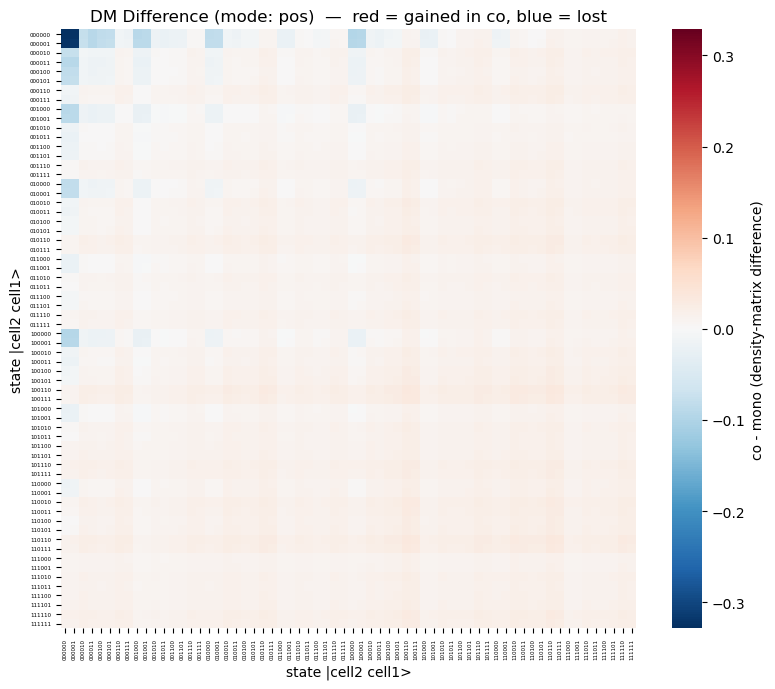


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------

Number of initial CNOT candidates: 30
Initial KL-divergence: 2.486456

  - Starting Efficiency-Optimized Search -

--- Iteration 1 | Current KL: 2.486456 ---


   - Single Insertion Phase: Added (0, 2) at index 0. New KL: 2.106416
  [Phase 1] Added Single: (0, 2) | New KL: 2.106416


  [Phase 2] Added Pair: ((0, 4), (0, 5)) | New KL: 1.451510



--- Iteration 2 | Current KL: 1.451510 ---


   - Single Insertion Phase: Added (0, 1) at index 0. New KL: 1.199277
  [Phase 1] Added Single: (0, 1) | New KL: 1.199277


...


--- Iteration 4 | Current KL: 0.739735 ---


   - Single Insertion Phase: Added (4, 0) at index 4. New KL: 0.687853
  [Phase 1] Added Single: (4, 0) | New KL: 0.687853



--- Iteration 5 | Current KL: 0.687853 ---


  - No improvements in any phase. Search Terminated.

--- Total Search Time: 243.10s ---

--- Pairwise Addition Result ---
Best sequence after addition: [(1, 2), (0, 1), (0, 2), (0, 4), (4, 0), (0, 5), (0, 3), (1, 0), (1, 5), (2, 1)]
KL sum after addition: 0.687853

Total search time: 243.41 seconds.

--- Starting CRX Angle Optimization (10 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 103   Least value of F = 0.6400988862058039   Constraint violation = 0.0
The corresponding X is:
[2.56078656 1.57090444 1.68393357 1.71913772 1.53929973 1.58228293
 1.60170544 1.58888521 1.64955239 1.54753084]
The constraint value is:
[-2.56078656 -1.57090444 -1.68393357 -1.71913772 -1.53929973 -1.58228293
 -1.60170544 -1.58888521 -1.64955239 -1.54753084 -0.58080609 -1.57068821
 -1.45765908 -1.42245493 -1.60229292 -1.55930972 -1.53988721 -1.55270744
 -1.49204026 -1.59406182]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['2.5608', '1.5709', '1.6839', '1.7191', '1.5393', '1.5823', '1.6017', '1.5889', '1.6496', '1.5475']
CRX Angle Optimization took: 7.23 seconds

--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------


--- Identifying Pot

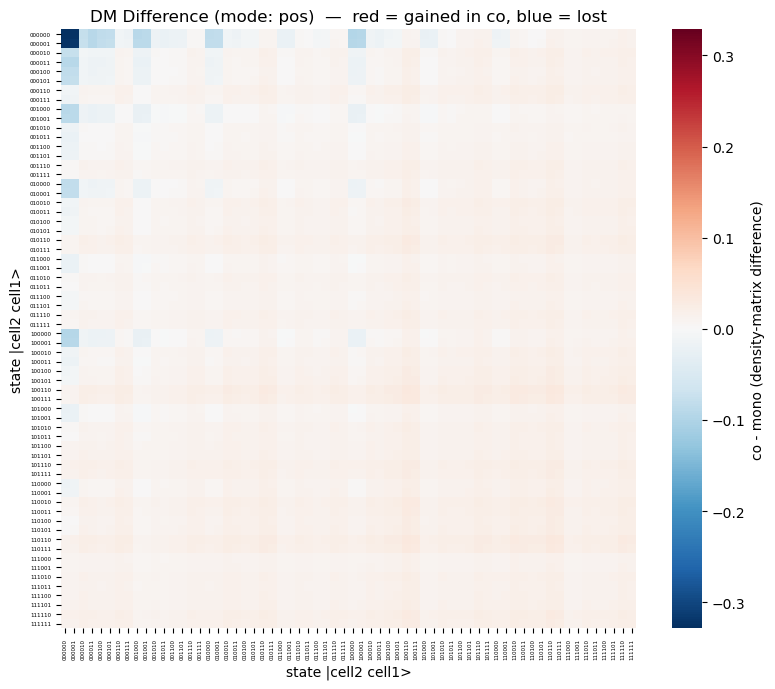


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------

Initial KL Divergence (no CNOTs): 2.486456

--- Building KL Divergence Matrix (30x30) ---
Calculating KL for single CNOTs (diagonal elements)...


Calculating KL for CNOT pairs (off-diagonal elements)...


Total CNOT pairs tested: 870
--- KL Divergence Matrix Built ---
Starting optimization with method: COBYLA


Iteration 0: Current cost: -2.2681361016259727


Iteration 20: Current cost: -2.3366780148839568


...

    --> Found a better KL on this path: 0.723385 at depth 10 with added CNOT (3, 2)


    --> Found a better KL on this path: 0.712930 at depth 11 with added CNOT (4, 5)


  Epoch 24 best KL Sum: 0.712930

--- Starting Epoch 25/25 (Addition) with CNOT: (4, 0) (KL: 2.487876) ---
  Skipping epoch: Single CNOT KL (2.487876) does not improve over baseline (2.486456).

Final Result: Best sequence found has 15 CNOTs (KL: 0.629694).

Total search took: 334.25 seconds.

Result for (Rank 1): Final KL Sum = 0.629694
  >>> NEW OVERALL BEST SOLUTION FOUND! <<<
  New best KL sum: 0.629694
  Origin: VQE solution at rank 1

--- Starting CRX Angle Optimization (15 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 136   Least value of F = 0.5784238391476304   Constraint violation = 0.0
The corresponding X is:
[2.56997043 1.49661656 1.56114622 1.51912941 1.5214166  1.42164686
 1.50872784 1.68727893 1.63365092 1.54844746 1.56394008 1.5149435
 1.55856004 2.67219223 1.39298628]
The constraint value is:
[-2.56997043 -1.49661656 -1.56114622 -1.51912941 -1.5214166  -1.42164686
 -1.50872784 -1.68727893 -1.63365092 -1.54844746 -1.56394008 -1.5149435
 -1.55856004 -2.67219223 -1.39298628 -0.57162223 -1.64497609 -1.58044643
 -1.62246324 -1.62017605 -1.71994579 -1.63286481 -1.45431373 -1.50794173
 -1.59314519 -1.57765257 -1.62664915 -1.58303262 -0.46940043 -1.74860637]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['2.5700', '1.4966', '1.5611', '1.5191', '1.5214', '1.4216', '1.5087', '1.6873', '1.6337', '1.

,algorithm,# gates,final KL,reduction,topology
0,multi_epoch,13,0.6038,1.8826,"[(2, 1), (0, 2), (0, 5), (0, 4), (0, 1), (0, 3..."
1,iterative_n_wise,10,0.6401,1.8464,"[(1, 2), (0, 1), (0, 2), (0, 4), (4, 0), (0, 5..."
2,vqe_hybrid,15,0.5784,1.9080,"[(2, 4), (0, 2), (0, 5), (0, 4), (0, 1), (0, 3..."


In [12]:
import dataclasses
import pandas as pd
from qxct import baseline_kl

ALGORITHMS = ["multi_epoch", "iterative_n_wise", "vqe_hybrid"]
algo_runs, rows = {}, []
for algo in ALGORITHMS:
    s = dataclasses.replace(config.search, algorithm=algo)
    cfg_a = dataclasses.replace(config, search=s)
    qx_a = QuantumXct(cfg_a, gene_list=gl_all)
    qx_a.encode(joint_counts_ct1_mo, joint_counts_ct2_mo, joint_counts_ct1_co, joint_counts_ct2_co)
    qx_a.screen_candidates()
    qx_a.search_topology()
    qx_a.optimize_angles()
    algo_runs[algo] = qx_a
    base = baseline_kl(qx_a.circ1, qx_a.circ2, qx_a.target1, qx_a.target2, cfg_a.backend.shots)
    rows.append({"algorithm": algo, "# gates": len(qx_a.result.topology),
                 "final KL": round(float(qx_a.result.kl_sum), 4),
                 "reduction": round(float(base - qx_a.result.kl_sum), 4),
                 "topology": qx_a.result.topology})

compare_df = pd.DataFrame(rows)
compare_df

## Three-scope benchmark on this dataset (GRN+LR / GRN-only / LR-only)

Runs the full search + angle optimization under each biological scope on the **simulated** data and reports the KL-reduction summary plus, per scope, the cumulative-ablation and isolated / leave-one-out contribution tables. CSVs go to `./benchmark_out_classic_sim/`.

- **GRN + LR** (`all`): full density-matrix-screened search over all links.
- **GRN-only** (`intra`): within-cell links, screened, optimized cell-by-cell.
- **LR-only** (`inter`): every cross-register pair, **no** density screening, **no** GRN.

In [13]:
import os
import pandas as pd
from qxct.analysis import compare_scopes

OUT_DIR = "results/classic_sim"
os.makedirs(OUT_DIR, exist_ok=True)

bench = compare_scopes(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all,
)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
bench["summary"].to_csv(os.path.join(OUT_DIR, "scope_summary.csv"), index=False)
bench["summary"]


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 30
Initial KL divergence (baseline): 2.486456



--- Starting Epoch 1/30 (Addition) with CNOT: (3, 5) (KL: 2.427692) ---


    --> Found a better KL on this path: 2.051647 at depth 2 with added CNOT (0, 2)


    --> Found a better KL on this path: 1.716767 at depth 3 with added CNOT (0, 4)


    --> Found a better KL on this path: 1.426912 at depth 4 with added CNOT (0, 5)


...

    --> Found a better KL on this path: 0.789420 at depth 9 with added CNOT (1, 2)


    --> Found a better KL on this path: 0.784707 at depth 10 with added CNOT (5, 0)


  Epoch 16 best KL Sum: 0.784707

Final Result: Best sequence found has 9 CNOTs (KL: 0.718328).

Total search took: 88.99 seconds.

--- Starting CRX Angle Optimization (9 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 94   Least value of F = 0.600942035570269   Constraint violation = 0.0
The corresponding X is:
[2.68501568 2.48785562 1.74173781 1.92259153 1.79789504 1.48509006
 1.49403438 1.62053608 1.63504979]
The constraint value is:
[-2.68501568 -2.48785562 -1.74173781 -1.92259153 -1.79789504 -1.48509006
 -1.49403438 -1.62053608 -1.63504979 -0.45657698 -0.65373703 -1.39985484
 -1.21900112 -1.34369762 -1.65650259 -1.64755827 -1.52105657 -1.50654286]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['2.6850', '2.4879', '1.7417', '1.9226', '1.7979', '1.4851', '1.4940', '1.6205', '1.6350']
CRX Angle Optimization took: 6.32 seconds


,Scope,Baseline KL,Final KL,KL Reduction,% Reduction,# Gates
0,GRN + LR,2.4865,0.6038,1.8826,75.7147,13
1,GRN only (intra),2.4865,1.9543,0.5322,21.4026,6
2,LR only (inter),2.4865,0.6009,1.8855,75.8314,9


[curate_lr_pairs] 0 LR pair(s) within the 6 test genes (resource='consensus'): []
[GRN+LR]  13 gates | baseline KL 2.4865 -> final KL 0.6038  (reduction 1.8826, 75.7%)

Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN         2.4865     0.0000                   0.0000         0.0000
    1 Gene_60 -> Gene_90           2.5999         2.3358    -0.1506                   0.1506         6.0576
    2 Gene_50 -> Gene_60           1.4896         1.9101    -0.4257                   0.5763        23.1779
    3 Gene_50 -> Gene_80           1.5526         1.5723    -0.3379                   0.9142        36.7672
    4 Gene_50 -> Gene_71           1.7078         1.2510    -0.3213                   1.2355        49.6894
    5 Gene_50 -> Gene_90           1.5993         1.0543    -0.1966                   1.4321        57.5973
    6 Gene_50 -> Gene_70           1.3323   

Saved histogram figure to results/classic_sim/all_occupancy_3way.png


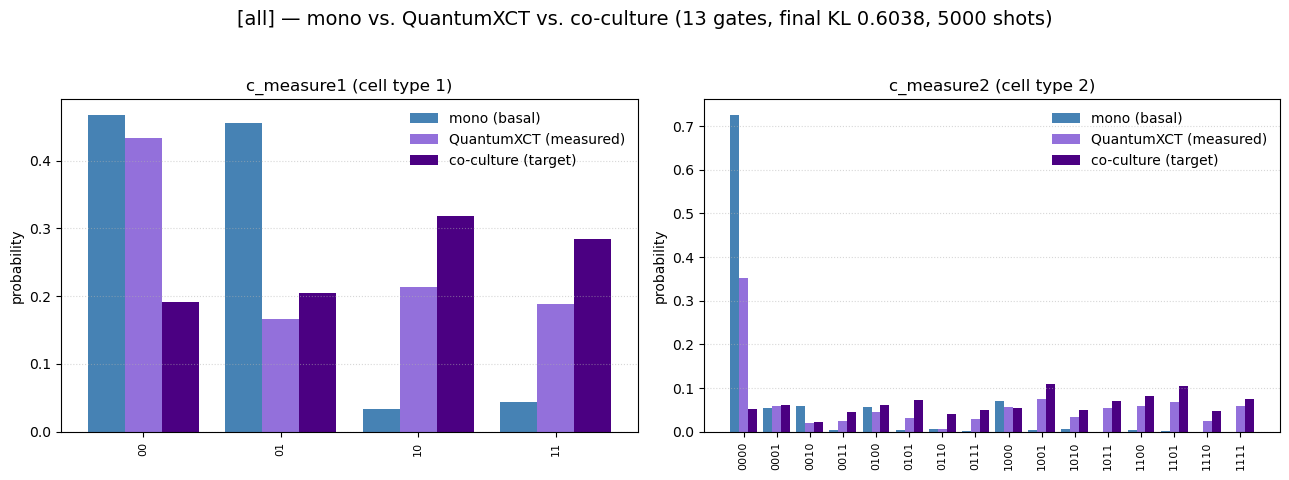


[all] optimized circuit (13 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
c_measure1: 2/»
              »
c_measure2: 4/»
              »
«                                                         ┌──────────────────────────────────────────────┐                                          »
«         q_0: ───────────────────────────────────────────┤0                                             ├──────────────────────────────────────────»
«                                                         │  Initialize(0.68337,0.67454,0.18439,0.20976) │                                          »
«         q_1: ───────────────────────────────────────────┤1                                             ├──────────────────────────────────────────»
«              ┌──────────────────────────────────────────┴────────────────────────────


--- Running circuit for: [all] optimized ---


Counts for c_measure1: {'01': 879, '00': 2055, '10': 1006, '11': 1060}
Counts for c_measure2: {'0101': 180, '0000': 1709, '1100': 250, '1011': 354, '0100': 201, '1001': 458, '1000': 330, '0001': 317, '1101': 333, '0011': 99, '1111': 279, '0111': 146, '0010': 101, '1110': 101, '1010': 115, '0110': 27}


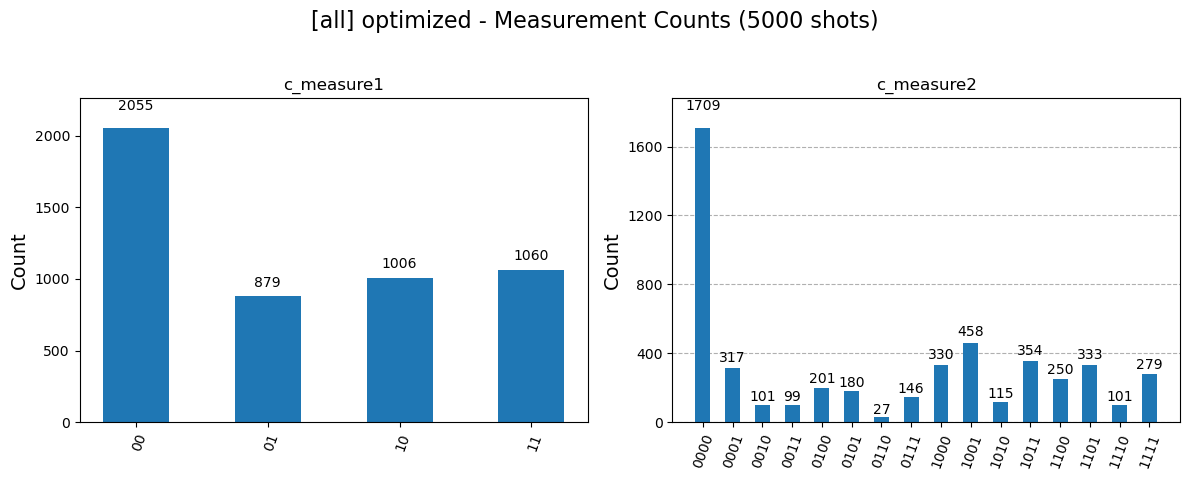

Histogram figure saved to results/classic_sim/all_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
    Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0      0  Baseline (0 gates)             nan        2.4865    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1      1  Gene_60 -> Gene_90          2.5999        2.3358   -0.1506                 -0.1506      2.3358             0.1506          6.06%                   6.06%                8.00%         148.96°
2      2  Gene_50 -> Gene_60          1.4896        1.9101   -0.4257                 -0.5763      2.1276             0.3588         17.12%                  14.43%               22.61%          85.35°
3      3  Gene_50 -> Gene_80          1.5526        1.5723   -0.3379                 -0.9142      2.1649             0.3215         13.59%         

Figure saved as results/classic_sim/all_relay_network.png


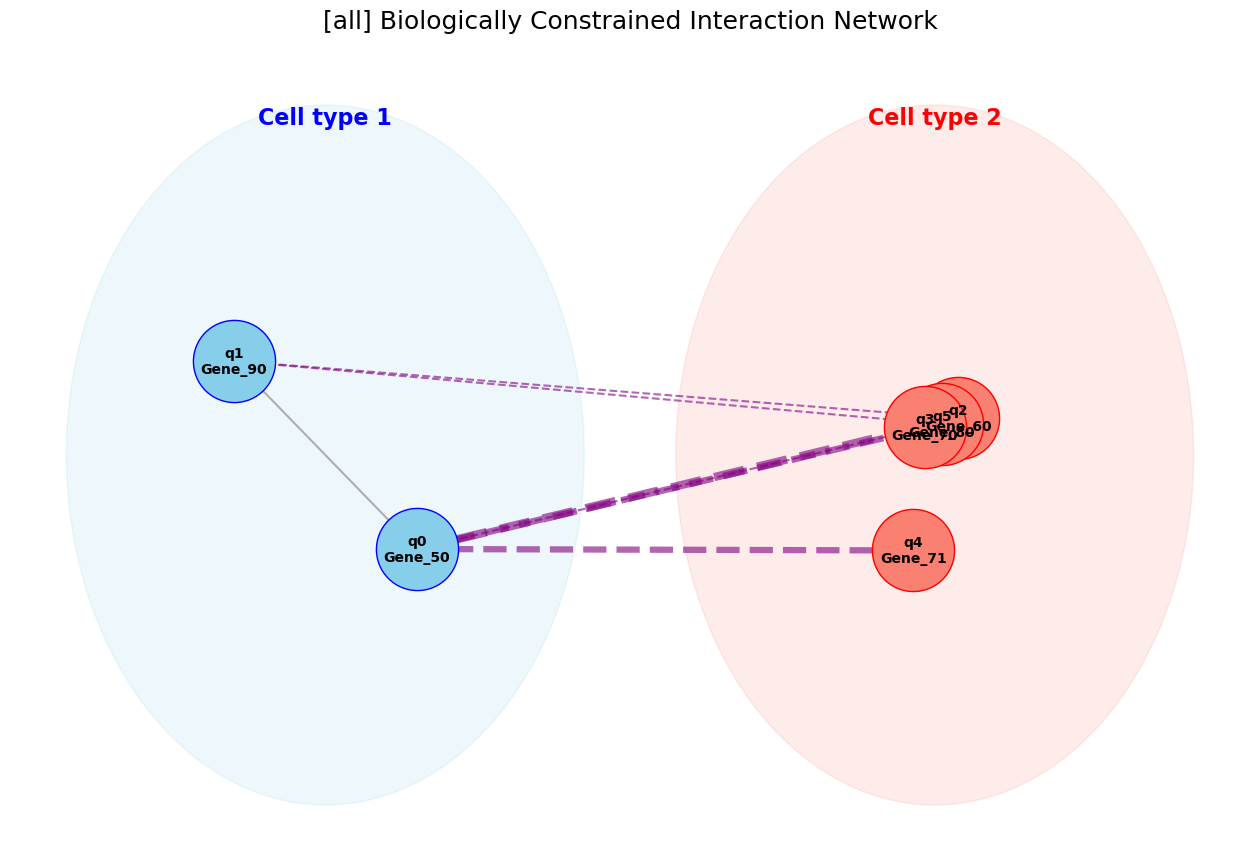

[GRN-only]  6 gates | baseline KL 2.4865 -> final KL 1.9543  (reduction 0.5322, 21.4%)

Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN         2.4865     0.0000                   0.0000         0.0000
    1 Gene_50 -> Gene_90           1.8099         2.2255    -0.2609                   0.2609        10.4943
    2 Gene_71 -> Gene_70           1.4573         2.2176    -0.0079                   0.2688        10.8115
    3 Gene_70 -> Gene_60           1.6011         2.1439    -0.0737                   0.3425        13.7751
    4 Gene_60 -> Gene_80           1.6051         2.0732    -0.0708                   0.4133        16.6218
    5 Gene_80 -> Gene_71           1.6256         1.9947    -0.0784                   0.4917        19.7759
    6 Gene_70 -> Gene_80           1.5995         1.9543    -0.0404                   0.5322        21.4026

Isolated / leave

Saved histogram figure to results/classic_sim/intra_occupancy_3way.png


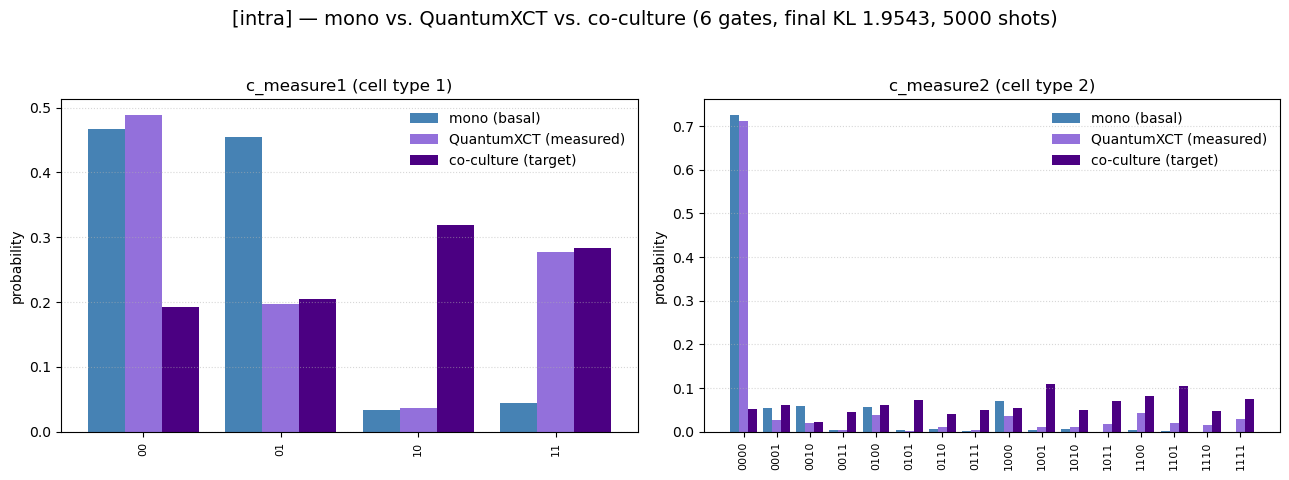


[intra] optimized circuit (6 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
c_measure1: 2/»
              »
c_measure2: 4/»
              »
«                                                         ┌──────────────────────────────────────────────┐                                          »
«         q_0: ───────────────────────────────────────────┤0                                             ├──────────────────────────────────────────»
«                                                         │  Initialize(0.68337,0.67454,0.18439,0.20976) │                                          »
«         q_1: ───────────────────────────────────────────┤1                                             ├──────────────────────────────────────────»
«              ┌──────────────────────────────────────────┴───────────────────────────

Counts for c_measure1: {'01': 1028, '00': 2290, '11': 1503, '10': 179}
Counts for c_measure2: {'0001': 151, '0000': 3611, '0100': 174, '0011': 14, '1100': 174, '1101': 88, '0110': 52, '1000': 182, '0010': 86, '1001': 72, '1110': 67, '1010': 68, '1011': 90, '1111': 137, '0111': 29, '0101': 5}


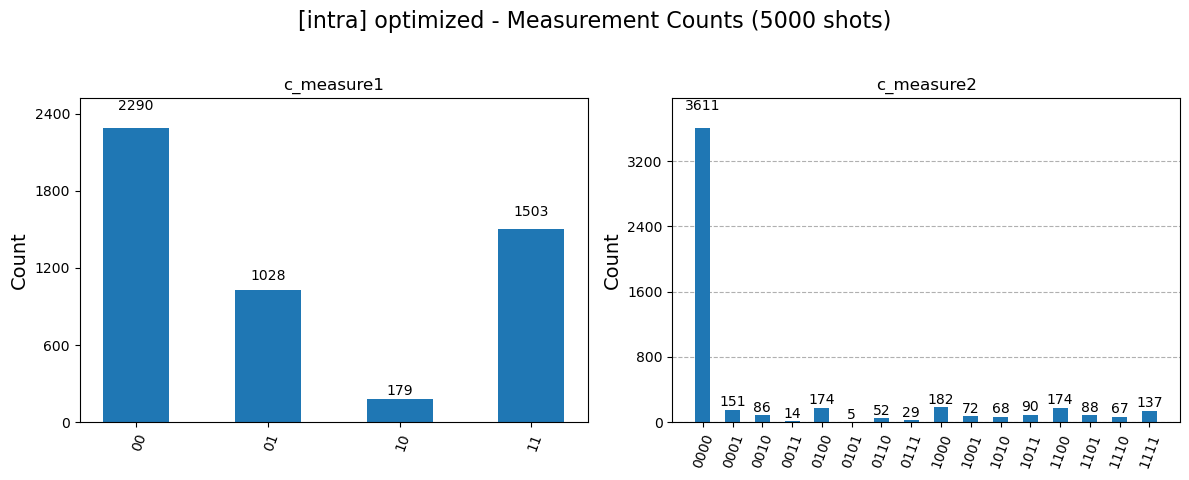

Histogram figure saved to results/classic_sim/intra_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        2.4865    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1  Gene_50 -> Gene_90          1.8099        2.2255   -0.2609                 -0.2609      2.2255             0.2609         10.49%                  10.49%               49.03%         103.70°
2     2  Gene_71 -> Gene_70          1.4573        2.2176   -0.0079                 -0.2688      2.4786             0.0079          0.32%                   0.32%                1.48%          83.50°
3     3  Gene_70 -> Gene_60          1.6011        2.1439   -0.0737                 -0.3425      2.4346             0.0518          2.96%              

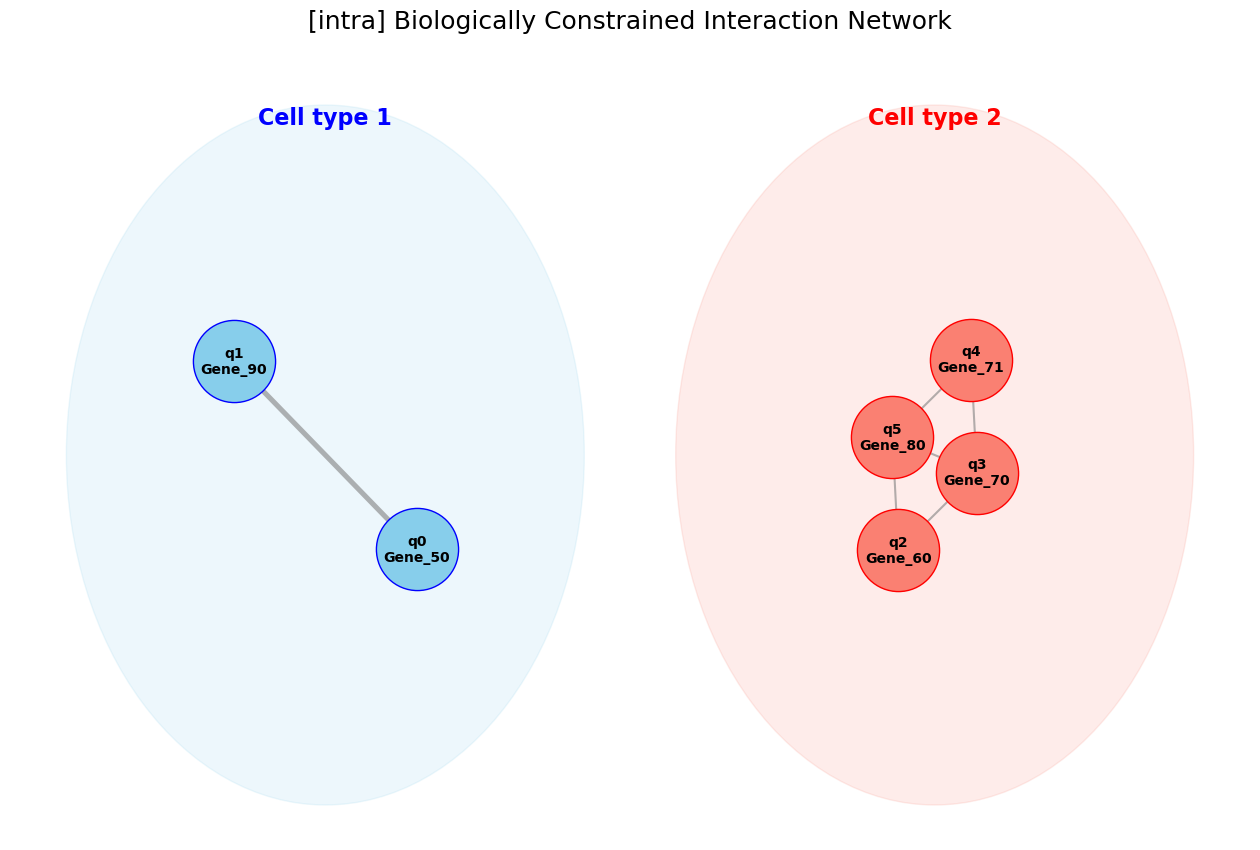

[LR-only]  9 gates | baseline KL 2.4865 -> final KL 0.6009  (reduction 1.8855, 75.8%)

Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN         2.4865     0.0000                   0.0000         0.0000
    1 Gene_80 -> Gene_90           2.6850         2.3007    -0.1858                   0.1858         7.4723
    2 Gene_50 -> Gene_60           2.4879         1.7797    -0.5210                   0.7068        28.4243
    3 Gene_50 -> Gene_80           1.7417         1.4013    -0.3784                   1.0852        43.6446
    4 Gene_50 -> Gene_71           1.9226         1.1477    -0.2536                   1.3388        53.8438
    5 Gene_60 -> Gene_90           1.7979         0.9328    -0.2149                   1.5537        62.4855
    6 Gene_50 -> Gene_70           1.4851         0.7809    -0.1518                   1.7055        68.5924
    7 Gene_70 -> G

Saved histogram figure to results/classic_sim/inter_occupancy_3way.png


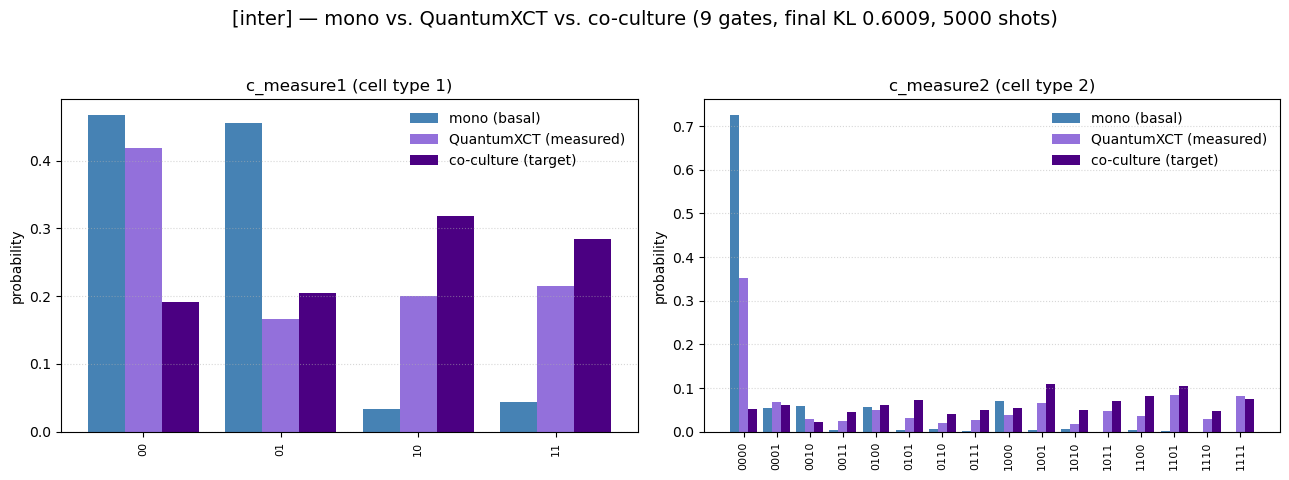


[inter] optimized circuit (9 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
c_measure1: 2/»
              »
c_measure2: 4/»
              »
«                                                         ┌──────────────────────────────────────────────┐                                          »
«         q_0: ───────────────────────────────────────────┤0                                             ├──────────────────────────────────────────»
«                                                         │  Initialize(0.68337,0.67454,0.18439,0.20976) │                                          »
«         q_1: ───────────────────────────────────────────┤1                                             ├──────────────────────────────────────────»
«              ┌──────────────────────────────────────────┴───────────────────────────


--- Running circuit for: [inter] optimized ---
Counts for c_measure1: {'01': 868, '00': 2002, '10': 924, '11': 1206}
Counts for c_measure2: {'1101': 464, '0000': 1729, '1100': 168, '1011': 256, '0100': 208, '0001': 326, '0010': 129, '0110': 74, '0011': 142, '1001': 385, '1110': 123, '1000': 188, '1111': 411, '0101': 165, '0111': 151, '1010': 81}


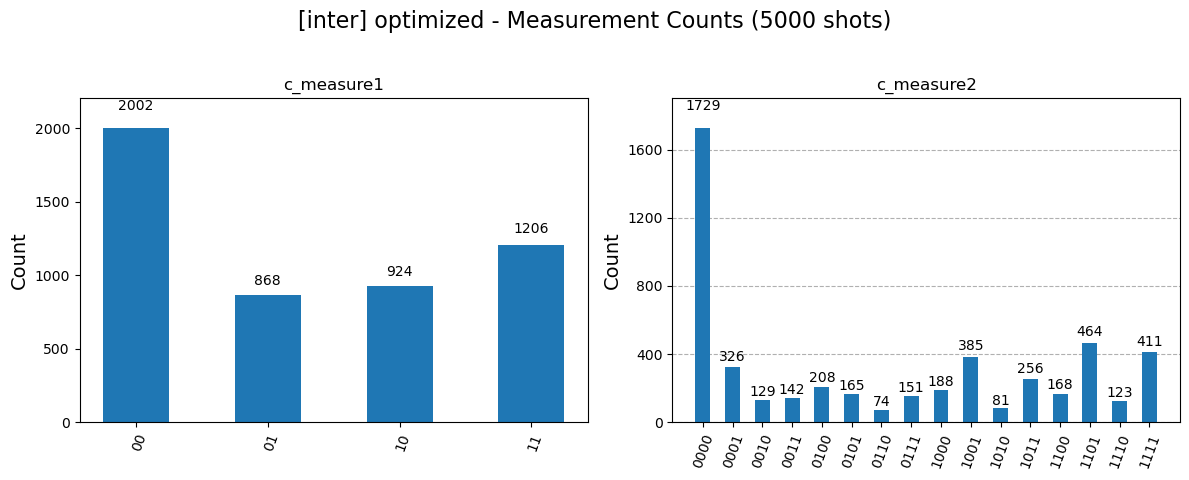

Histogram figure saved to results/classic_sim/inter_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        2.4865    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1  Gene_80 -> Gene_90          2.6850        2.3007   -0.1858                 -0.1858      2.3007             0.1858          7.47%                   7.47%                9.85%         153.84°
2     2  Gene_50 -> Gene_60          2.4879        1.7797   -0.5210                 -0.7068      1.9647             0.5217         20.95%                  20.98%               27.63%         142.54°
3     3  Gene_50 -> Gene_80          1.7417        1.4013   -0.3784                 -1.0852      2.1267             0.3598         15.22%              

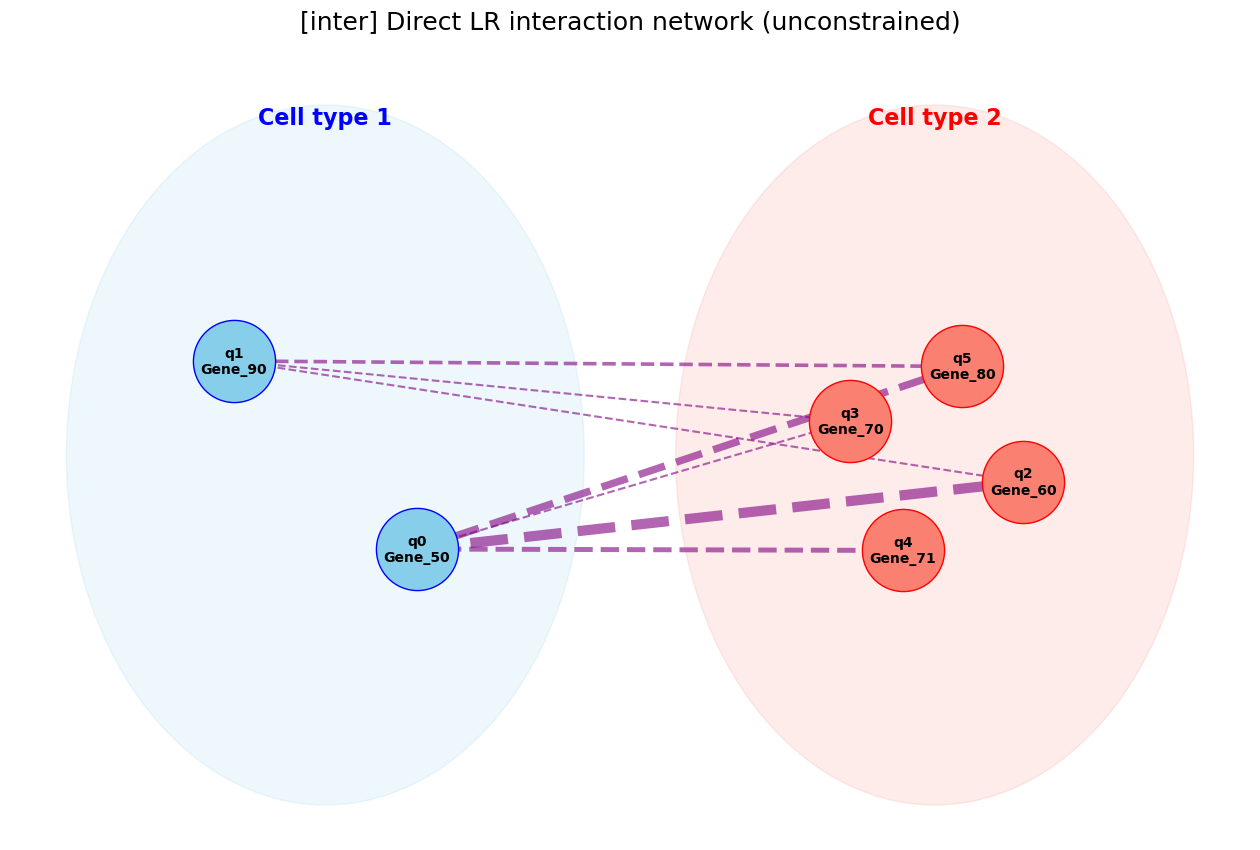

In [14]:
from qxct.analysis import plot_scope_report
gl_ct1_report, gl_ct2_report = gl_ct1, gl_ct2
from qxct.resources import curate_lr_pairs
# LR pairs auto-curated from the Dimitrov/LIANA consensus DB, intersected with the
# genes in this test (replaces hand-curated pairs; plotting only).
valid_lr_pairs = curate_lr_pairs(gl_all, resource_csv="LR_databases/Human-merged-Jin-Dimitrov-LR-pairs.csv")
ct1_name, ct2_name = 'Cell type 1', 'Cell type 2'
# --- self-contained: (re)compute `bench` if it is not in the kernel, so this
# cell works on its own even after a kernel restart or out-of-order run ---
try:
    bench
except NameError:
    bench = compare_scopes(
        config,
        joint_counts_ct1_mo, joint_counts_ct2_mo,
        joint_counts_ct1_co, joint_counts_ct2_co,
        gene_list=gl_all,
    )

for scope, res in bench["detail"].items():
    tag = {"all": "GRN+LR", "intra": "GRN-only", "inter": "LR-only"}[scope]
    print("=" * 72)
    print(f"[{tag}]  {res['n_gates']} gates | baseline KL {res['baseline_kl']:.4f} "
          f"-> final KL {res['final_kl']:.4f}  (reduction {res['reduction']:.4f}, {res['pct_reduction']:.1f}%)")
    print("=" * 72)
    print("\nCumulative ablation reduction:")
    print(res["cumulative_ablation"].to_string(index=False))
    print("\nIsolated / leave-one-out gate contribution:")
    print(res["isolated_contribution"].to_string(index=False))
    res["cumulative_ablation"].to_csv(os.path.join(OUT_DIR, f"{scope}_cumulative_ablation.csv"), index=False)
    res["isolated_contribution"].to_csv(os.path.join(OUT_DIR, f"{scope}_isolated_contribution.csv"), index=False)
    # Full per-scope figure report: occupancy, optimized circuit,
    # measurement histograms, and interaction network by cell type.
    plot_scope_report(
        res, gl_ct1=gl_ct1_report, gl_ct2=gl_ct2_report,
        valid_lr_pairs=valid_lr_pairs, out_dir=OUT_DIR, scope=scope,
        ct1_name=ct1_name, ct2_name=ct2_name,
    )


In [15]:
# Inspect any single scope further, e.g. the LR-only isolated contribution:
bench["detail"]["inter"]["isolated_contribution"]

,Gate,CRX Angle (rad),Isolated KL,Isolated Reduction,LOO KL (without gate),Marginal Contribution,% Marginal of Baseline
0,Gene_50 -> Gene_80,1.7417,2.1267,0.3598,0.9708,0.3699,14.8760
1,Gene_50 -> Gene_71,1.9226,2.0544,0.4321,0.9183,0.3174,12.7643
2,Gene_50 -> Gene_60,2.4879,1.9647,0.5217,0.8664,0.2655,10.6759
3,Gene_50 -> Gene_70,1.4851,2.3240,0.1624,0.8383,0.2374,9.5460
4,Gene_60 -> Gene_90,1.7979,2.3755,0.1109,0.8095,0.2086,8.3887
5,Gene_70 -> Gene_90,1.4940,2.4046,0.0818,0.6822,0.0813,3.2700
6,Gene_70 -> Gene_50,1.6350,2.4883,-0.0018,0.6763,0.0753,3.0290
7,Gene_90 -> Gene_60,1.6205,2.3850,0.1015,0.6713,0.0704,2.8303
8,Gene_80 -> Gene_90,2.6850,2.3007,0.1858,0.6563,0.0553,2.2252


## Benchmark B — baseline methods (QuantumXCT vs OT vs TN transform vs Born machine)

Compares four methods on the **simulated** data using the **same per-register KL** to the co-culture target (KL_cell1 + KL_cell2), plus number of parameters, runtime, whether the method is **conditioned on the basal state** (models the transition, rather than free-fitting the target), and whether it yields an **interpretable interaction network**.

- **Optimal Transport** (POT / entropic Sinkhorn): transports basal to co, barycentric pushforward binned to the grid.
- **TN transform** (quimb MPO): learned `|psi_pred> = MPO @ |psi_basal>` — the fair classical analog of the QuantumXCT circuit, conditioned on basal, capacity set by `tn_bond_dim` (1 = product/limited).
- **Born machine** (quimb MPS): Born probabilities fit to the co target **directly** (not conditioned on basal) — an oracle/upper-bound reference.

QuantumXCT is scored by **sampling** its circuit (as on real hardware, which returns samples not a statevector); the classical baselines are exact. Requires `pot` and `quimb` (in `environment.yml`).

In [16]:
from qxct.baselines import compare_baselines

benchB = compare_baselines(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all,
    ot_reg=0.05,
    tn_bond_dim=1,     # 1 = capacity-limited product transform; raise for more capacity
    born_bond_dim=2,
)
benchB["summary"]


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 30
Initial KL divergence (baseline): 2.486456

--- Starting Epoch 1/30 (Addition) with CNOT: (3, 5) (KL: 2.427692) ---


    --> Found a better KL on this path: 2.051647 at depth 2 with added CNOT (0, 2)


    --> Found a better KL on this path: 1.716767 at depth 3 with added CNOT (0, 4)


    --> Found a better KL on this path: 1.426912 at depth 4 with added CNOT (0, 5)


    --> Found a better KL on this path: 1.172687 at depth 5 with added CNOT (5, 1)


...

    --> Found a better KL on this path: 0.723385 at depth 10 with added CNOT (3, 2)


    --> Found a better KL on this path: 0.712930 at depth 11 with added CNOT (4, 5)


  Epoch 29 best KL Sum: 0.712930

--- Starting Epoch 30/30 (Addition) with CNOT: (4, 0) (KL: 2.487876) ---
  Skipping epoch: Single CNOT KL (2.487876) does not improve over baseline (2.486456).

Final Result: Best sequence found has 13 CNOTs (KL: 0.631689).

Total search took: 530.86 seconds.

--- Starting CRX Angle Optimization (13 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 102   Least value of F = 0.6038441088051916   Constraint violation = 0.0
The corresponding X is:
[2.59988692 1.48961407 1.55261333 1.70777216 1.59928581 1.33229384
 1.43339784 1.52200584 1.62177818 1.48747869 1.48185839 1.52331609
 1.54396385]
The constraint value is:
[-2.59988692 -1.48961407 -1.55261333 -1.70777216 -1.59928581 -1.33229384
 -1.43339784 -1.52200584 -1.62177818 -1.48747869 -1.48185839 -1.52331609
 -1.54396385 -0.54170574 -1.65197859 -1.58897933 -1.43382049 -1.54230684
 -1.80929881 -1.70819481 -1.61958681 -1.51981447 -1.65411397 -1.65973426
 -1.61827657 -1.5976288 ]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['2.5999', '1.4896', '1.5526', '1.7078', '1.5993', '1.3323', '1.4334', '1.5220', '1.6218', '1.4875', '1.4819', '1.5233', '1.5440']
CRX Angle Optimization took: 7.

,Method,KL (cell1+cell2),# params,param type,runtime (s),conditioned on basal,interpretable network
0,QuantumXCT,0.6038,13,CRX gates,537.9310,yes,yes
1,Optimal Transport,2.1064,272,transport-plan entries,0.0050,yes,no
2,TN transform,0.0021,24,MPO tensor params (D=1),0.6500,yes,no
3,Born machine,0.0032,32,MPS tensor params (D=2),0.1050,no,no


In [17]:
# Per-register detail for any method (cell1, cell2):
for m in ["Optimal Transport", "TN transform", "Born machine"]:
    r1, r2 = benchB["detail"][m]["per_register"]
    print(f"{m:18s} cell1 KL={r1['kl']:.4f} | cell2 KL={r2['kl']:.4f}")
print("QuantumXCT topology:", benchB["detail"]["QuantumXCT"]["topology"])

Optimal Transport  cell1 KL=0.5074 | cell2 KL=1.5990
TN transform       cell1 KL=0.0000 | cell2 KL=0.0021
Born machine       cell1 KL=0.0000 | cell2 KL=0.0032
QuantumXCT topology: [(2, 1), (0, 2), (0, 5), (0, 4), (0, 1), (0, 3), (1, 0), (1, 5), (1, 2), (3, 5), (5, 1), (3, 0), (5, 2)]


### Synthetic edge & direction recovery
Compare the discovered topology against the known ground-truth network of the synthetic benchmark (signaling path 50→60→70→80→90 + autonomous module 73→74, 73→75). Reports precision, recall, direction accuracy and AUC; saves tables + a figure to the results folder.

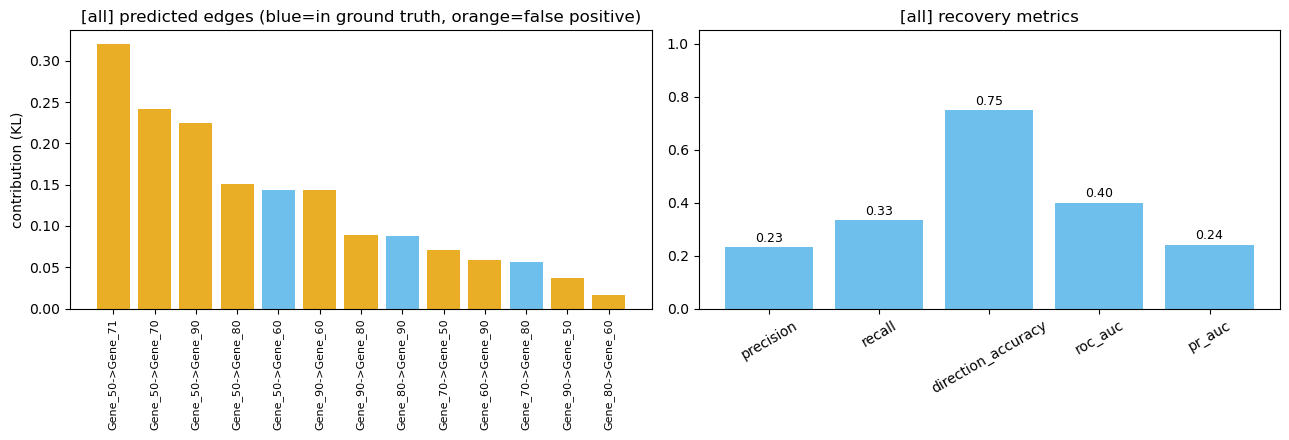

,scope,n_predicted,n_ground_truth,n_ground_truth_testable,precision,recall,recall_testable,direction_accuracy,roc_auc,pr_auc,null_expected_TP,hypergeom_p,contribution_col
0,all,13,9,5,0.2308,0.3333,0.6000,0.7500,0.4000,0.2409,2.1670,0.3673,Marginal Contribution


In [18]:
# Synthetic edge & direction recovery vs the known ground-truth network
from qxct.metrics import evaluate_edge_recovery, synthetic_ground_truth
try:
    bench
except NameError:
    bench = compare_scopes(
        config,
        joint_counts_ct1_mo, joint_counts_ct2_mo,
        joint_counts_ct1_co, joint_counts_ct2_co,
        gene_list=gl_all,
    )
res_all = bench["detail"]["all"]
recovery = evaluate_edge_recovery(
    topology=res_all["topology"],
    gene_list=gl_all,
    ground_truth_edges=synthetic_ground_truth(),   # 50->60->70->80->90 + 73->74, 73->75
    contribution_df=res_all["isolated_contribution"],
    out_dir=OUT_DIR, scope_tag="all", show=True,
)
recovery["summary"]


### Benchmark: L1 vs L2 encoding (scaling logic)
Two ways to turn gene counts into amplitudes:

- **L2** (original paper, Eqs. 1–2): amplitude = count / ‖count‖₂, so measurement probability ∝ **count²** — it *emphasizes common (high-count) states*.
- **L1** (QuantumXCT default): amplitude = √(count / Σcount), so measurement probability = the empirical **frequency** (count / total) — *frequency-preserving*.

Because L1 and L2 define different target distributions, each norm's own KL is not comparable across norms. So we report: the **own-encoding KL** (what the search optimized against), a **common-reference KL** = the optimized circuit's measured output vs the true empirical co-culture frequency (both norms on one yardstick), and **edge-recovery** metrics vs the known synthetic ground-truth network (encoding-independent).


--- CNOT Analysis (pos) ---
Max Signal: 0.0350
Candidates Found: 30 / 30
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 30
Initial KL divergence (baseline): 2.486456

--- Starting Epoch 1/30 (Addition) with CNOT: (3, 5) (KL: 2.427692) ---


    --> Found a better KL on this path: 2.051647 at depth 2 with added CNOT (0, 2)


    --> Found a better KL on this path: 1.716767 at depth 3 with added CNOT (0, 4)


    --> Found a better KL on this path: 1.426912 at depth 4 with added CNOT (0, 5)


    --> Found a better KL on this path: 1.172687 at depth 5 with added CNOT (5, 1)


...

    --> Found a better KL on this path: 1.515332 at depth 9 with added CNOT (3, 0)


  Epoch 29 best KL Sum: 1.515332

--- Starting Epoch 30/30 (Addition) with CNOT: (4, 0) (KL: 4.244523) ---
  Skipping epoch: Single CNOT KL (4.244523) does not improve over baseline (4.243495).

Final Result: Best sequence found has 13 CNOTs (KL: 1.465117).

Total search took: 417.13 seconds.

--- Starting CRX Angle Optimization (13 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 95   Least value of F = 1.4334064531242379   Constraint violation = 0.0
The corresponding X is:
[1.43068099 1.67155294 1.56721572 2.53818933 1.59864329 1.57417762
 1.56120188 1.59345575 1.52039967 1.52524721 1.56317422 1.56328317
 1.52222325]
The constraint value is:
[-1.43068099 -1.67155294 -1.56721572 -2.53818933 -1.59864329 -1.57417762
 -1.56120188 -1.59345575 -1.52039967 -1.52524721 -1.56317422 -1.56328317
 -1.52222325 -1.71091166 -1.47003972 -1.57437694 -0.60340333 -1.54294936
 -1.56741504 -1.58039077 -1.54813691 -1.62119299 -1.61634545 -1.57841843
 -1.57830948 -1.6193694 ]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.4307', '1.6716', '1.5672', '2.5382', '1.5986', '1.5742', '1.5612', '1.5935', '1.5204', '1.5252', '1.5632', '1.5633', '1.5222']
CRX Angle Optimization took: 6.6


--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
    Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0      0  Baseline (0 gates)             nan        4.2435    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1      1  Gene_90 -> Gene_70          1.4307        4.2335   -0.0100                 -0.0100      4.2335             0.0100          0.23%                   0.23%                0.35%          81.97°
2      2  Gene_50 -> Gene_71          1.6716        3.6045   -0.6290                 -0.6390      3.6151             0.6284         14.82%                  14.81%               22.39%          95.77°
3      3  Gene_50 -> Gene_60          1.5672        3.0689   -0.5356                 -1.1746      3.6525             0.5910         12.62%         

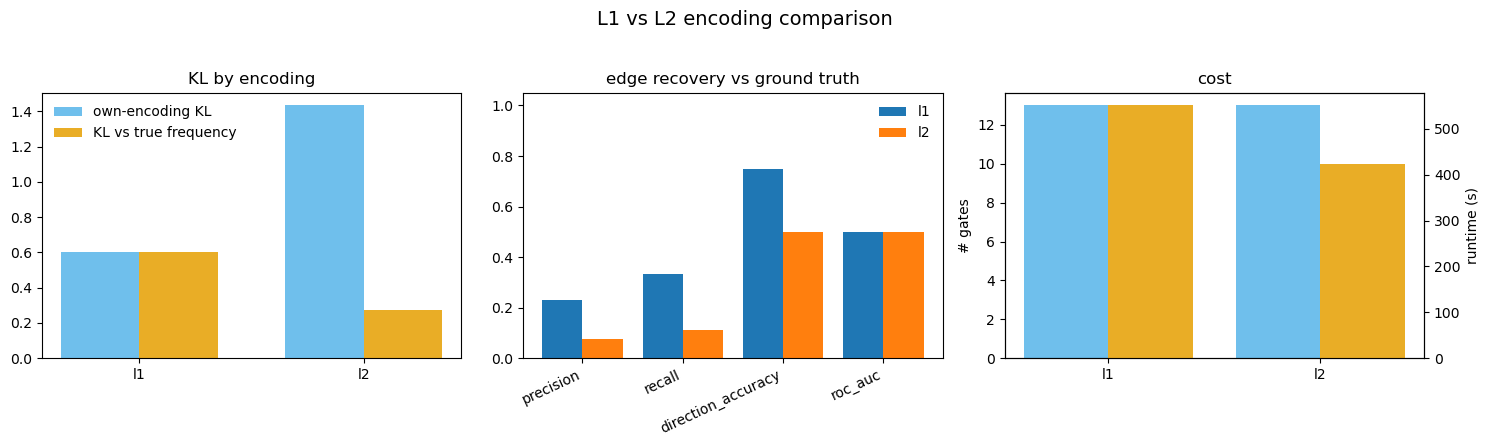

,norm,scope,n_gates,own_baseline_kl,own_final_kl,own_pct_reduction,ref_kl_vs_frequency,runtime_s,precision,recall,direction_accuracy,roc_auc
0,l1,all,13,2.4865,0.6038,75.7100,0.6038,550.8200,0.2308,0.3333,0.7500,0.5000
1,l2,all,13,4.2435,1.4334,66.2200,0.2725,423.7700,0.0769,0.1111,0.5000,0.5000


In [19]:
# L1 vs L2 encoding comparison on the simulated cells
from qxct.analysis import compare_norms
from qxct.metrics import synthetic_ground_truth
norm_cmp = compare_norms(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all,
    norms=("l1", "l2"),
    scope="all",
    ground_truth_edges=synthetic_ground_truth(),   # 50->60->70->80->90 + 73->74, 73->75
    out_dir=os.path.join(OUT_DIR, "norm_comparison"),
    show=True,
)
norm_cmp["summary"]
